In [1]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Literal
from dotenv import load_dotenv
from pydantic import BaseModel, Field
from langchain_deepseek import ChatDeepSeek

In [3]:
load_dotenv()

True

In [4]:
model = llm = ChatDeepSeek(model="deepseek-chat")

In [5]:
class SupportCategory(BaseModel):
    category:Literal['refund','delivery','technical']
    

In [6]:
class SupportState(TypedDict):
    message:str
    category:Literal['refund','delivery','technical']
    response:str
    
    

In [7]:
structured_model=model.with_structured_output(SupportCategory)


In [14]:
def classify_message(state: SupportState):
    prompt=f""" Classify the following customer message into one of these categories:
    refund, delivery, technical.
    message: {state['message']}"""
    
    result=structured_model.invoke(prompt)
    
    return {"category":result.category}

In [8]:
def check_category(state: SupportState) ->Literal['refund_node','delivery_node','technical_node']:
    
    if state['category']=='refund':
        return "refund_node"
    elif state['category']=="delivery":
        return "delivery_node"
    else:
        return "technical_node"
    

In [10]:
def refund_node(state: SupportState):
    prompt="""  You are a customer support assistant.

    The customer wants a refund.

    Customer message:
    {state["message"]}

    Write a polite and helpful response explaining that
    their refund request has been received and will be processed. """
    
    result=model.invoke(prompt)
    
    return {"response":result.content}

In [11]:
def delivery_node(state: SupportState):
    
    prompt="""  You are a customer support assistant.

    The customer has a delivery-related issue.

    Customer message:
    {state["message"]}

    Write a polite and helpful response addressing the customer's
    delivery concern. Ask for the order number if necessary.
    """

    result = model.invoke(prompt)

    return {
        "response": result.content
    }  

In [12]:
def technical_node(sate:SupportState):
    prompt=""" You are a customer support assistant.

    The customer has a technical-related issue.

    Customer message:
    {state["message"]}

    Write a polite and helpful response addressing the customer's
    technical concern. Ask for the order number if necessary.
    """

    result = model.invoke(prompt)

    return {
        "response": result.content
    }

In [15]:
graph=StateGraph(SupportState)

graph.add_node('classify_message',classify_message)
graph.add_node('refund_node',refund_node)
graph.add_node('delivery_node',delivery_node)
graph.add_node('technical_node',technical_node)

graph.add_edge( START,'classify_message')
graph.add_conditional_edges('classify_message',check_category)
graph.add_edge('refund_node',END)
graph.add_edge('delivery_node',END)
graph.add_edge('technical_node',END)

workflow=graph.compile()




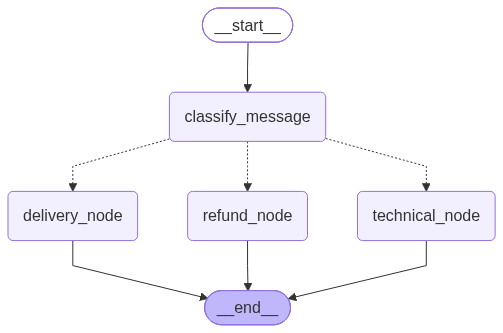

In [16]:
workflow

In [18]:
user_toold={
    "message":"hello ! i have a percel when its come  "
}
workflow.invoke(user_toold)

{'message': 'hello ! i have a percel when its come  ',
 'category': 'delivery',
 'response': "Of course, I'd be happy to help you with your delivery concern. \n\nTo assist you as quickly and accurately as possible, could you please provide me with your **order number**? \n\nOnce I have that, I can look into the details of your shipment and work on a solution for you right away. \n\nThank you for your patience, and I apologize for any inconvenience this may have caused. We're here to help!"}